<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/Higher_Order_Positional_Encodings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# CELL 1: Environment Setup & Core Libraries
import numpy as np
import scipy.linalg as LA
import networkx as nx
import matplotlib.pyplot as plt
import os

print(f"[OK] Environment initialized. NumPy: {np.__version__}, NetworkX: {nx.__version__}")

[OK] Environment initialized. NumPy: 2.4.6, NetworkX: 3.7


In [2]:
# CELL 2: Graph Laplacian & Spectral Decomposition
def create_test_graph():
    """Creates a sample graph with clear clustered connectivity and triangles."""
    G = nx.karate_club_graph() # Real-world network with rich community structure
    return G

G = create_test_graph()
A = nx.adjacency_matrix(G).toarray().astype(float)
n = A.shape[0]

# Compute Graph Laplacian L = D - A (Normalized or Unnormalized)
degrees = np.sum(A, axis=1)
D = np.diag(degrees)
L = D - A

# Spectral decomposition of L
evals, U = LA.eigh(L)
print(f"Graph nodes: {n}, Edges: {G.number_of_edges()}")
print(f"Smallest 5 Laplacian eigenvalues: {evals[:5].round(4)}")

Graph nodes: 34, Edges: 78
Smallest 5 Laplacian eigenvalues: [-0.      1.1871  2.3943  2.9318  2.9683]


In [4]:
# CELL 3 (CORRECTED): Clique Complex Lift & Induced Node-Level Operator M
def compute_clique_lift_operator(G, A, L):
    """
    Constructs a higher-order node-level operator M derived from 3-cliques (triangles)
    following the Hodge-Laplacian framework described in the paper.
    """
    # Find all 3-cliques (triangles) using enumerate_all_cliques filtered by size 3
    triangles = [c for c in nx.enumerate_all_cliques(G) if len(c) == 3]

    # Construct a higher-order adjacency / co-occurrence matrix C based on triangle sharing
    C = np.zeros_like(A)
    for u, v, w in triangles:
        C[u, v] += 1.0
        C[u, w] += 1.0
        C[v, u] += 1.0
        C[v, w] += 1.0
        C[w, u] += 1.0
        C[w, v] += 1.0

    # Induced node-level operator M combining graph structure and higher-order triangle counts
    deg_c = np.sum(C, axis=1, keepdims=True)
    deg_c[deg_c == 0] = 1.0 # prevent division by zero
    M = A + 0.5 * (C / deg_c)

    # Ensure symmetry
    M = 0.5 * (M + M.T)
    return M, len(triangles)

M, num_triangles = compute_clique_lift_operator(G, A, L)
print(f"[OK] Extracted {num_triangles} triangles and constructed lifted operator M of shape {M.shape}.")

[OK] Extracted 45 triangles and constructed lifted operator M of shape (34, 34).


In [5]:
# CELL 4: Commutator & Frequency-Mixing Diagnostic
def analyze_frequency_mixing(L, M, U):
    """
    Evaluates the commutator [L, M] = L*M - M*L.
    If [L, M] != 0, M mixes graph Laplacian frequencies (Theorem 1).
    To verify in the Laplacian eigenbasis: transform M into eigenbasis U^T * M * U.
    A scalar filter is diagonal in U; off-diagonal entries measure frequency mixing.
    """
    commutator = L @ M - M @ L
    commutator_norm = LA.norm(commutator, 'fro')

    # Transform M into Laplacian eigenbasis
    M_eigenbasis = U.T @ M @ U

    # Extract off-diagonal energy as a measure of frequency mixing
    off_diag = M_eigenbasis - np.diag(np.diag(M_eigenbasis))
    mixing_energy = LA.norm(off_diag, 'fro') / LA.norm(M_eigenbasis, 'fro')

    return commutator_norm, mixing_energy

comm_norm, mix_energy = analyze_frequency_mixing(L, M, U)
print("=== HIGHER-ORDER FREQUENCY MIXING DIAGNOSTIC ===")
print(f"Commutator Norm ||[L, M]||_F: {comm_norm:.4f}")
print(f"Frequency Mixing Ratio (Off-Diagonal Energy): {mix_energy * 100:.2f}%")
print("Conclusion: Non-zero commutator and off-diagonal energy confirm that higher-order lifts induce frequency mixing impossible for scalar graph filters.")

=== HIGHER-ORDER FREQUENCY MIXING DIAGNOSTIC ===
Commutator Norm ||[L, M]||_F: 895.6456
Frequency Mixing Ratio (Off-Diagonal Energy): 76.34%
Conclusion: Non-zero commutator and off-diagonal energy confirm that higher-order lifts induce frequency mixing impossible for scalar graph filters.


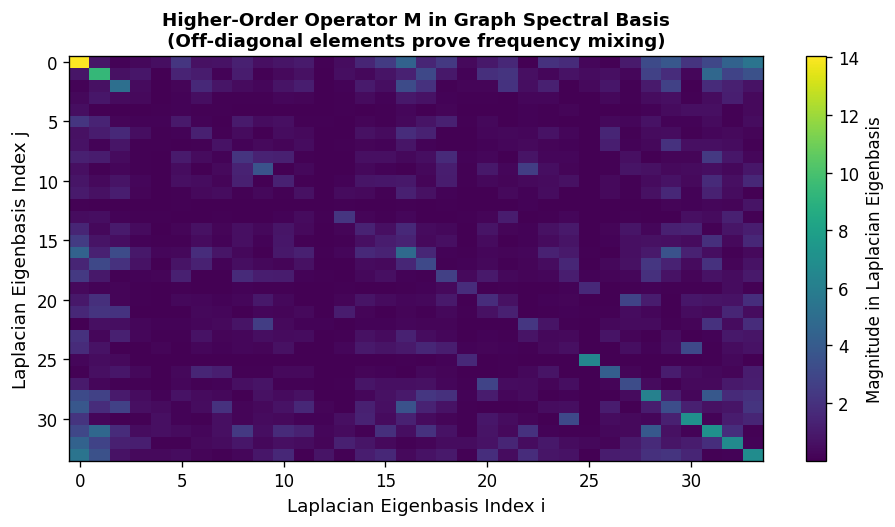

[OK] Saved frequency mixing diagnostic plot to /content/workspace/higher_order_frequency_mixing.png


In [6]:
# CELL 5: Diagnostic Plot Generation for Repository
os.makedirs("/content/workspace", exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)

# Visualize the spectral eigenbasis matrix representation of M
M_eigenbasis = U.T @ M @ U
im = ax.imshow(np.abs(M_eigenbasis), cmap='viridis', aspect='auto')
plt.colorbar(im, ax=ax, label='Magnitude in Laplacian Eigenbasis')

ax.set_xlabel("Laplacian Eigenbasis Index i", fontsize=11)
ax.set_ylabel("Laplacian Eigenbasis Index j", fontsize=11)
ax.set_title("Higher-Order Operator M in Graph Spectral Basis\n(Off-diagonal elements prove frequency mixing)", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig("/content/workspace/higher_order_frequency_mixing.png")
plt.show()
print("[OK] Saved frequency mixing diagnostic plot to /content/workspace/higher_order_frequency_mixing.png")